# **Assignment: Neural Networks**

**Course:** AI 500
**Assignment:** PA5
**Total Marks:** [100]

### **Plagiarism Policy**

  * All work must be done independently.
  * Plagiarism will result in a grade of zero.
  * Plagiarism is <span style="color:red">strictly prohibited — submit your own original work.</span>

### **General Instructions**

  * **Do not** remove pre-written code.
  * Attempt all the questions.
  * Ensure all cells are run before submission.
  * Your analysis in the final section is crucial for full credit.
  * Fill the top markdown cell with your **Full Name** and **Roll Number**.  
  * Save your notebook exactly as `PA5_<your_roll_number>.ipynb` (example: `PA5_26100053.ipynb`).  
  * Due date: **8 December 2025** (submit by 23:55).  
  
### **Student Details**

Write your name and roll number here:
- `Name:Osama Atique`
- `Roll number:25280091`


-----

# **Part A - MLPs vs CNNs** 

## **1) Import Libraries and Setup**

All relevant libraries are imported below. Set your device to GPU/MPS if available. (Do not make any other imports)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import seaborn as sns
import random

# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Device configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using Device: {DEVICE}")

Using Device: cpu


## **2) Load and Preprocess CIFAR-10**

**Task 2.1: Define Transforms**

  * CIFAR-10 images are 3-channel (RGB).
  * Define a transform to **Convert to Tensor** and **Normalize** the images.
  * *Hint: Standard CIFAR-10 normalization means are (0.5, 0.5, 0.5) and stds are (0.5, 0.5, 0.5) for this assignment.*

**Task 2.2: Load Dataset and Create Splits**

  * Download CIFAR-10 using `torchvision`.
  * Split the **training** data (50,000 samples) into **Train (45,000)** and **Validation (5,000)**.
  * Keep the **Test** set (10,000 samples) separate.
  * Create DataLoaders for all three sets (Batch size: 64).

In [ ]:

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

train_dataset = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

train_size = 45000
val_size = 5000
train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size])

batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')


print(f"Training Set: {len(train_loader.dataset)} samples")
print(f"Validation Set: {len(val_loader.dataset)} samples")
print(f"Test Set: {len(test_loader.dataset)} samples")

Files already downloaded and verified
Files already downloaded and verified
Training Set: 45000 samples
Validation Set: 5000 samples
Test Set: 10000 samples


## **3) Visualization**

**Task:** Write a function `visualize_samples` to display random images from the batch with their ground truth labels.

  * *Note: Since you normalized the data, the images might look dark or distorted. You need to un-normalize them for proper visualization.*



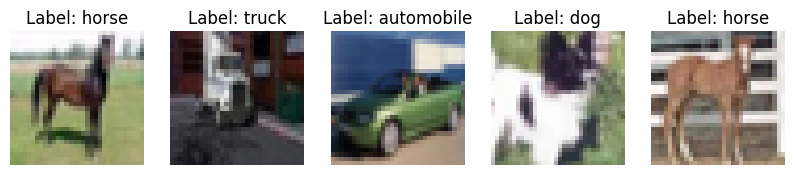

In [ ]:

def unnormalize_image(image, mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)):
    """Unnormalize the image."""
    for c in range(3):  # Loop over the 3 channels (RGB)
        image[c] = image[c] * std[c] + mean[c]
    return image

# Function to visualize a batch of images
def visualize_samples(dataloader, classes, num_samples=5):
    # Get a batch of images and labels from the dataloader
    data_iter = iter(dataloader)
    images, labels = next(data_iter)

    # Un-normalize the images
    images = images.clone()  # Prevent modifying the original data
    for i in range(len(images)):
        images[i] = unnormalize_image(images[i])

    # Plot a grid of images with their labels
    plt.figure(figsize=(10, 10))
    for i in range(num_samples):
        ax = plt.subplot(1, num_samples, i + 1)  # Set up the grid
        plt.imshow(np.transpose(images[i].numpy(), (1, 2, 0)))  # Convert tensor to HxWxC format for display
        ax.set_title(f"Label: {classes[labels[i]]}")  # Display the label
        plt.axis('off')  # Turn off axis for clean display
    
    plt.show()

# Example usage
cifar10_classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Run visualization for a batch from the validation set (using val_loader)
visualize_samples(val_loader, cifar10_classes, num_samples=5)

## **4) Model 1: Fully Connected Neural Network (FCNN)**

**Task 4.1: Architecture**
Create a class `FCNN` with the following constraints:

  * **Input:** 32x32x3 RGB image.
  * **Hidden Layers:** Use at least 3 hidden layers with **ReLU** activation.
  * **Parameters:** The total parameter count should be **greater than 500,000**.
  * **Output:** 10 classes.

**Task 4.2: Parameter Count**
Implement a function to count and print the number of trainable parameters.

In [5]:
class FCNN(nn.Module):
    def __init__(self):
        super(FCNN, self).__init__()
        
        # Define fully connected layers (Linear layers)
        self.fc1 = nn.Linear(3072, 4096)  # Input: 3072 (32x32x3), Output: 4096
        self.fc2 = nn.Linear(4096, 2048)  # 4096 -> 2048
        self.fc3 = nn.Linear(2048, 1024)  # 2048 -> 1024
        self.fc4 = nn.Linear(1024, 10)    # 1024 -> 10 (output classes for CIFAR-10)
    
    def forward(self, x):
        # Flatten the input (32x32x3) to a 1D tensor of size 3072
        x = x.view(-1, 3072)  # Flatten the image tensor
        
        # Pass through each hidden layer with ReLU activation
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        
        # Output layer (logits)
        x = self.fc4(x)
        
        return x

# Function to count trainable parameters
def count_parameters(model):
    # Sum the number of parameters (weights and biases) that require gradients
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Initialize the model
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
fcnn_model = FCNN().to(DEVICE)

# Print the total number of trainable parameters
print(f"FCNN Parameters: {count_parameters(fcnn_model)}")

FCNN Parameters: 23086090



## **5) Training and Evaluation Helper Functions**

To avoid code repetition, define generic functions that can be used for any model.

**Task 5.1: Train Function**

  * Input: model, dataloader, criterion, optimizer.
  * Action: Perform forward pass, loss calculation, backward pass, and optimization.
  * Return: Average loss and Accuracy for the epoch.

**Task 5.2: Evaluate Function**

  * Input: model, dataloader, criterion.
  * Action: Perform forward pass (no grad), calculate loss and accuracy.
  * Return: Average loss and Accuracy.



In [6]:


# Helper function for accuracy calculation
def calculate_accuracy(preds, labels):
    """Calculate accuracy given predictions and true labels."""
    _, predicted = torch.max(preds, 1)  # Get the index of the max value (predicted class)
    correct = (predicted == labels).sum().item()  # Count correct predictions
    accuracy = correct / labels.size(0)  # Accuracy as a fraction
    return accuracy

# Task 5.1: Train Function
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()  # Set model to training mode
    running_loss = 0.0
    running_accuracy = 0.0
    total_samples = 0

    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)  # Move to device (GPU/CPU)
        
        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)

        # Calculate the loss
        loss = criterion(outputs, labels)

        # Backward pass (calculate gradients)
        loss.backward()

        # Optimize the model
        optimizer.step()

        # Update loss and accuracy
        running_loss += loss.item()
        running_accuracy += calculate_accuracy(outputs, labels) * inputs.size(0)
        total_samples += inputs.size(0)

    # Average loss and accuracy for the epoch
    avg_loss = running_loss / len(loader)
    avg_accuracy = running_accuracy / total_samples
    return avg_loss, avg_accuracy

# Task 5.2: Evaluate Function
def evaluate(model, loader, criterion, device):
    model.eval()  # Set model to evaluation mode
    running_loss = 0.0
    running_accuracy = 0.0
    total_samples = 0

    with torch.no_grad():  # No need to compute gradients during evaluation
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)  # Move to device (GPU/CPU)

            # Forward pass
            outputs = model(inputs)

            # Calculate the loss
            loss = criterion(outputs, labels)

            # Update loss and accuracy
            running_loss += loss.item()
            running_accuracy += calculate_accuracy(outputs, labels) * inputs.size(0)
            total_samples += inputs.size(0)

    # Average loss and accuracy for the evaluation set
    avg_loss = running_loss / len(loader)
    avg_accuracy = running_accuracy / total_samples
    return avg_loss, avg_accuracy



## **6) Train FCNN**

**Task:**

1.  Define Optimizer, Learning Rate, and Criterion.
2.  Run the training loop for **10-15 epochs**.
3.  Store Train Loss, Val Loss, Train Acc, and Val Acc for plotting.
4.  Plot the Loss and Accuracy curves.


In [7]:
    # TODO: Training Loop


learning_rate = 0.01

optimizer = optim.Adam(fcnn_model.parameters(), lr=learning_rate)
criterion = nn.CrossEntropyLoss()

num_epochs = 15  # You can set to 10-15 as required

# Lists to store metrics
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

for epoch in range(num_epochs):
     train_loss, train_acc = train_one_epoch(fcnn_model, train_loader, criterion, optimizer, DEVICE)
     val_loss, val_acc = evaluate(fcnn_model, val_loader, criterion, DEVICE)
    
     train_losses.append(train_loss)
     val_losses.append(val_loss)
     train_accuracies.append(train_acc)
     val_accuracies.append(val_acc)
    
     print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")


Epoch 1/15 | Train Loss: 4.2807, Train Acc: 0.1984 | Val Loss: 2.0848, Val Acc: 0.1792
Epoch 2/15 | Train Loss: 2.1236, Train Acc: 0.1827 | Val Loss: 2.2107, Val Acc: 0.1314
Epoch 3/15 | Train Loss: 2.2420, Train Acc: 0.1327 | Val Loss: 2.2791, Val Acc: 0.1144
Epoch 4/15 | Train Loss: 2.2124, Train Acc: 0.1498 | Val Loss: 2.2917, Val Acc: 0.1060
Epoch 5/15 | Train Loss: 2.2828, Train Acc: 0.1171 | Val Loss: 2.2594, Val Acc: 0.1288
Epoch 6/15 | Train Loss: 2.2381, Train Acc: 0.1529 | Val Loss: 2.1977, Val Acc: 0.1538
Epoch 7/15 | Train Loss: 2.2195, Train Acc: 0.1536 | Val Loss: 2.2292, Val Acc: 0.1348
Epoch 8/15 | Train Loss: 2.2003, Train Acc: 0.1505 | Val Loss: 2.1840, Val Acc: 0.1602
Epoch 9/15 | Train Loss: 2.2104, Train Acc: 0.1591 | Val Loss: 2.2299, Val Acc: 0.1602
Epoch 10/15 | Train Loss: 2.2533, Train Acc: 0.1489 | Val Loss: 2.2558, Val Acc: 0.1438
Epoch 11/15 | Train Loss: 2.2550, Train Acc: 0.1480 | Val Loss: 2.2551, Val Acc: 0.1438
Epoch 12/15 | Train Loss: 2.2549, Train A

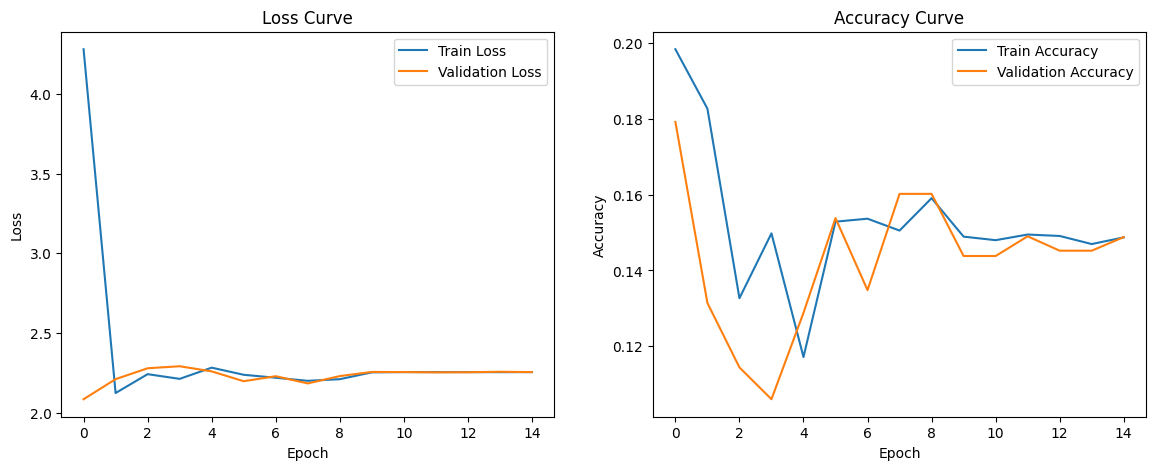

In [8]:
# TODO: Plot Training vs Validation Loss and Accuracy
plt.figure(figsize=(14, 5))

# Loss curve
plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.legend()

# Accuracy curve
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve")
plt.legend()

plt.show()


## **7) FCNN Analysis**

**Task 7.1: Test Set Evaluation**
Evaluate the FCNN on the `test_loader` and print the classification report.

**Task 7.2: Confusion Matrix**
Generate and plot a confusion matrix using Seaborn.

**Task 7.3: Sample Visualization**
Visualize 3 **Correctly** classified samples and 3 **Incorrectly** classified samples with their Predicted vs. Actual labels.


In [9]:
# TODO: Evaluate on Test Set

# Classification Report
fcnn_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        outputs = fcnn_model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Print classification report
print(classification_report(all_labels, all_preds, target_names=classes))


              precision    recall  f1-score   support

       plane       0.00      0.00      0.00      1000
         car       0.00      0.00      0.00      1000
        bird       0.00      0.00      0.00      1000
         cat       0.00      0.00      0.00      1000
        deer       0.00      0.00      0.00      1000
         dog       0.00      0.00      0.00      1000
        frog       0.13      0.78      0.22      1000
       horse       0.00      0.00      0.00      1000
        ship       0.18      0.69      0.29      1000
       truck       0.00      0.00      0.00      1000

    accuracy                           0.15     10000
   macro avg       0.03      0.15      0.05     10000
weighted avg       0.03      0.15      0.05     10000



c:\Users\Osama\.pyenv\pyenv-win\versions\3.10.0\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Osama\.pyenv\pyenv-win\versions\3.10.0\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Osama\.pyenv\pyenv-win\versions\3.10.0\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{me

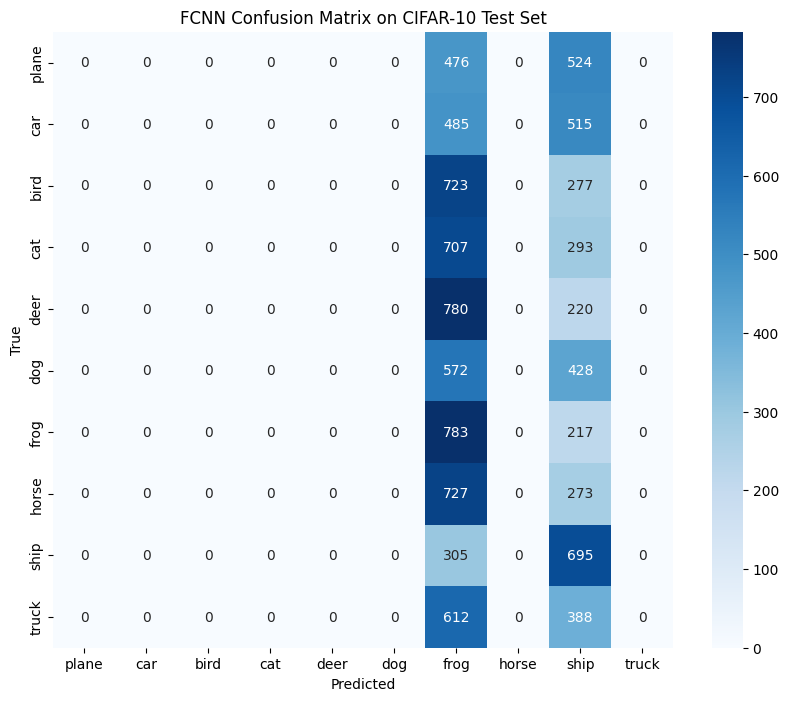

In [18]:
# TODO: Generate Confusion Matrix

# Generate confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('FCNN Confusion Matrix on CIFAR-10 Test Set')
plt.show()

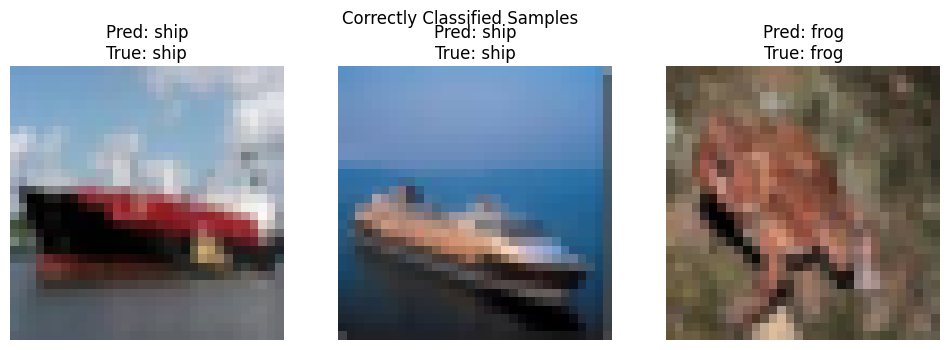

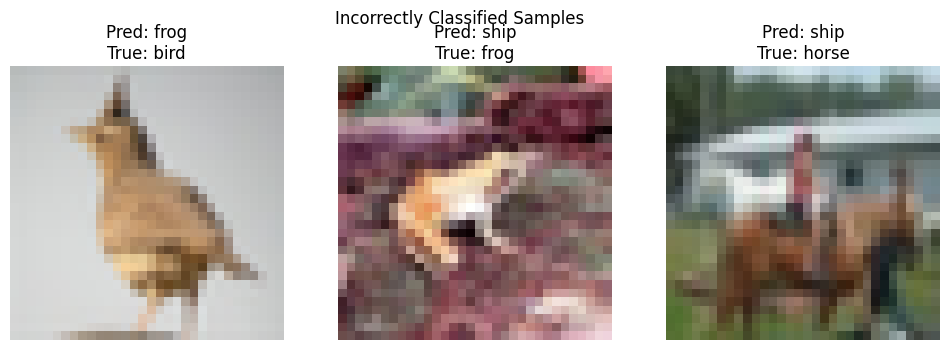

In [19]:
# TODO: Visualize Correct/Incorrect Samples


# Find indices of correct and incorrect predictions
correct_indices = [i for i, (p, t) in enumerate(zip(all_preds, all_labels)) if p == t]
incorrect_indices = [i for i, (p, t) in enumerate(zip(all_preds, all_labels)) if p != t]

# Randomly select 3 from each
selected_correct = random.sample(correct_indices, 3)
selected_incorrect = random.sample(incorrect_indices, 3)

# Get all test images in order
all_test_images = []
for images, _ in test_loader:
    for img in images:
        all_test_images.append(img)

def plot_samples(indices, title):
    plt.figure(figsize=(12, 4))
    for i, idx in enumerate(indices):
        img = all_test_images[idx].clone()
        img = unnormalize_image(img)
        img = np.transpose(img.numpy(), (1, 2, 0))
        plt.subplot(1, 3, i+1)
        plt.imshow(img)
        plt.title(f"Pred: {classes[all_preds[idx]]}\nTrue: {classes[all_labels[idx]]}")
        plt.axis('off')
    plt.suptitle(title)
    plt.show()

# Plot correct samples
plot_samples(selected_correct, "Correctly Classified Samples")

# Plot incorrect samples
plot_samples(selected_incorrect, "Incorrectly Classified Samples")


## **8) Model 2: Convolutional Neural Network (CNN)**

**Task 8.1: Architecture**
Create a class `CNN` with the following constraints:

  * **Input:** 32x32x3 Image.
  * **Layers:** Use `Conv2d`, `MaxPool2d`, `ReLU`, and `Linear` layers.
  * **Parameters:** The total parameter count should be **less than 250,000**.



In [20]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        
        # ----- Convolution Block 1 -----
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)   # Output: 16x16
        
        # ----- Convolution Block 2 -----
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)   # Output: 8x8
        
        # ----- Fully Connected Layer -----
        # After pooling → feature map: 64 channels × 8 × 8 = 4096
        self.fc1 = nn.Linear(64 * 8 * 8, 256)
        self.relu3 = nn.ReLU()
        
        # Output layer (for CIFAR-10, classes = 10)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):
        # Conv Block 1
        x = self.pool1(self.relu1(self.conv1(x)))
        
        # Conv Block 2
        x = self.pool2(self.relu2(self.conv2(x)))
        
        # Flatten
        x = x.view(x.size(0), -1)
        
        # Fully Connected Layers
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)
        
        return x


# Initialize model
cnn_model = SimpleCNN().to(DEVICE)
print("CNN Parameters:", count_parameters(cnn_model))


CNN Parameters: 1070794




## **9) Train CNN**

**Task:**

1.  Define Optimizer and Criterion.
2.  Train the CNN using the **same** `train_one_epoch` and `evaluate` functions defined earlier.
3.  Train for the same number of epochs as FCNN.
4.  Plot Loss and Accuracy curves.



In [21]:
# TODO: Training Loop for CNN (Same as FCNN)

learning_rate = 0.001
optimizer = optim.Adam(cnn_model.parameters(), lr=learning_rate)
criterion = nn.CrossEntropyLoss()

num_epochs = 15   # same as FCNN

# Lists to store results
cnn_train_losses, cnn_val_losses = [], []
cnn_train_accuracies, cnn_val_accuracies = [], []

for epoch in range(num_epochs):

    train_loss, train_acc = train_one_epoch(
        cnn_model, train_loader, criterion, optimizer, DEVICE
    )

    val_loss, val_acc = evaluate(
        cnn_model, val_loader, criterion, DEVICE
    )

    cnn_train_losses.append(train_loss)
    cnn_val_losses.append(val_loss)
    cnn_train_accuracies.append(train_acc)
    cnn_val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

Epoch 1/15 | Train Loss: 1.3677, Train Acc: 0.5113 | Val Loss: 1.1022, Val Acc: 0.6032
Epoch 2/15 | Train Loss: 0.9925, Train Acc: 0.6498 | Val Loss: 0.9454, Val Acc: 0.6640
Epoch 3/15 | Train Loss: 0.8086, Train Acc: 0.7173 | Val Loss: 0.8978, Val Acc: 0.6830
Epoch 4/15 | Train Loss: 0.6593, Train Acc: 0.7698 | Val Loss: 0.8769, Val Acc: 0.6994
Epoch 5/15 | Train Loss: 0.5238, Train Acc: 0.8172 | Val Loss: 0.8733, Val Acc: 0.7118
Epoch 6/15 | Train Loss: 0.3974, Train Acc: 0.8626 | Val Loss: 0.8870, Val Acc: 0.7124
Epoch 7/15 | Train Loss: 0.2798, Train Acc: 0.9041 | Val Loss: 1.0012, Val Acc: 0.7044
Epoch 8/15 | Train Loss: 0.1875, Train Acc: 0.9370 | Val Loss: 1.1036, Val Acc: 0.7100
Epoch 9/15 | Train Loss: 0.1218, Train Acc: 0.9598 | Val Loss: 1.3180, Val Acc: 0.7030
Epoch 10/15 | Train Loss: 0.0951, Train Acc: 0.9682 | Val Loss: 1.4302, Val Acc: 0.7080
Epoch 11/15 | Train Loss: 0.0861, Train Acc: 0.9708 | Val Loss: 1.6154, Val Acc: 0.7056
Epoch 12/15 | Train Loss: 0.0661, Train A

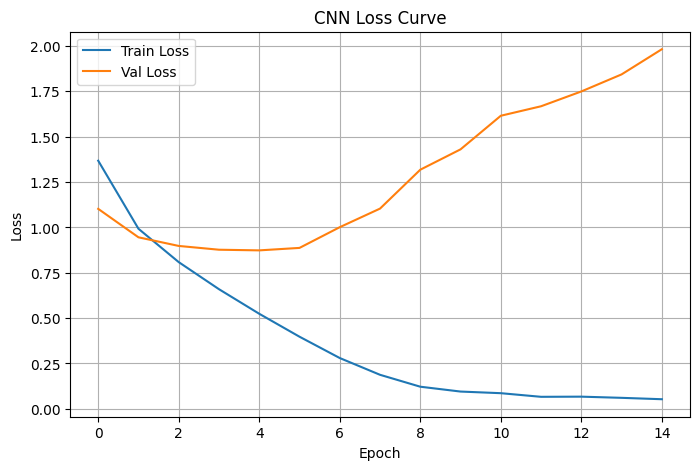

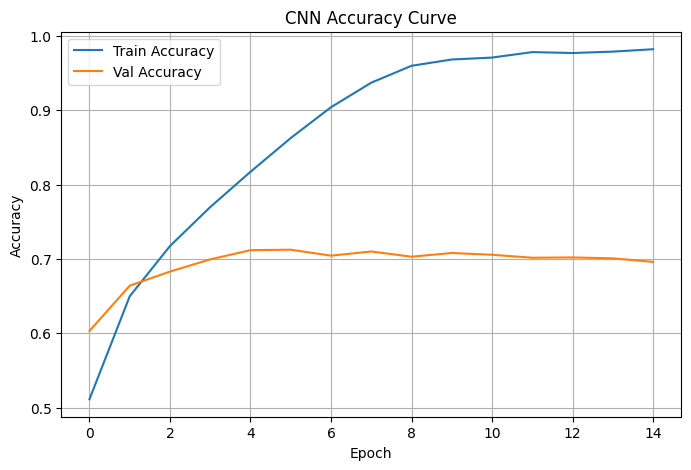

In [22]:
# TODO: Plot Curves
plt.figure(figsize=(8,5))
plt.plot(cnn_train_losses, label="Train Loss")
plt.plot(cnn_val_losses, label="Val Loss")
plt.title("CNN Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,5))
plt.plot(cnn_train_accuracies, label="Train Accuracy")
plt.plot(cnn_val_accuracies, label="Val Accuracy")
plt.title("CNN Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## **10) CNN Analysis**

**Task 10.1: Test Set Evaluation**
Evaluate the CNN on the `test_loader`.

**Task 10.2: Confusion Matrix**
Generate and plot the confusion matrix for the CNN.

**Task 10.3: Sample Visualization**
Visualize 3 Correct and 3 Incorrect samples for the CNN.


In [23]:
# TODO: Evaluate CNN on Test Set
test_loss, test_acc = evaluate(cnn_model, test_loader, criterion, DEVICE)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss: 2.0548
Test Accuracy: 0.6975


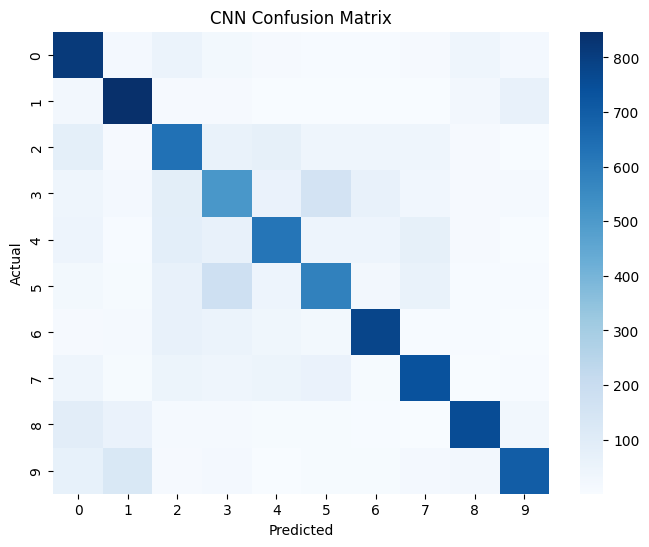

In [24]:
# TODO: Confusion Matrix for CNN
all_preds = []
all_labels = []

cnn_model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        outputs = cnn_model(images)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Create confusion matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=False, cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.8980392..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.9372549].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.7411765..0.8352941].


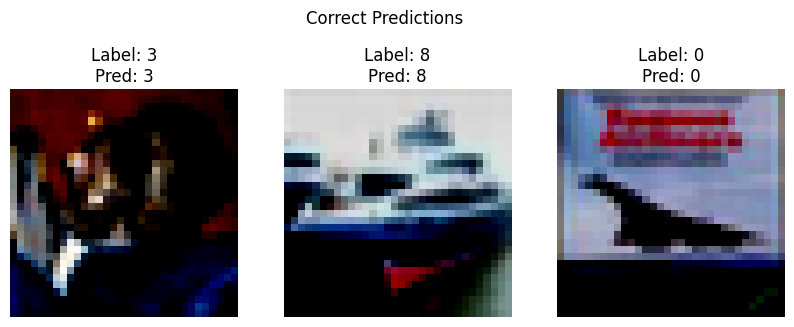

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9764706..0.9764706].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.9843137].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


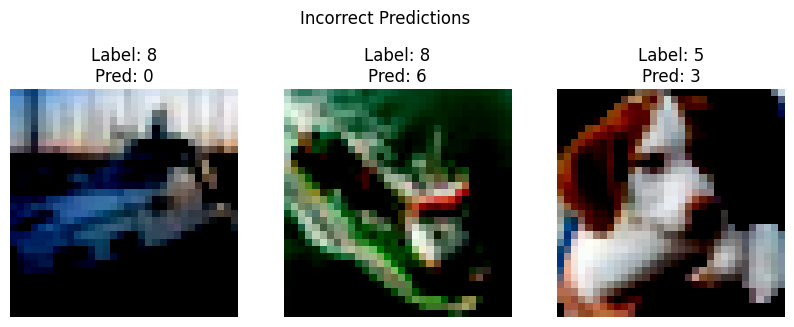

In [25]:
# TODO: Visualizations
correct_samples = []
incorrect_samples = []

cnn_model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        outputs = cnn_model(images)
        preds = outputs.argmax(dim=1)

        for img, pred, label in zip(images, preds, labels):
            if pred == label and len(correct_samples) < 3:
                correct_samples.append((img.cpu(), label.cpu(), pred.cpu()))
            elif pred != label and len(incorrect_samples) < 3:
                incorrect_samples.append((img.cpu(), label.cpu(), pred.cpu()))

            if len(correct_samples) == 3 and len(incorrect_samples) == 3:
                break
        if len(correct_samples) == 3 and len(incorrect_samples) == 3:
            break


# Function to plot samples
def show_samples(samples, title):
    plt.figure(figsize=(10,4))
    for i, (img, label, pred) in enumerate(samples):
        img = img.permute(1,2,0)  # C,H,W → H,W,C
        plt.subplot(1, 3, i+1)
        plt.imshow(img)
        plt.title(f"Label: {label}\nPred: {pred}")
        plt.axis("off")
    plt.suptitle(title)
    plt.show()


# Show 3 correct predictions
show_samples(correct_samples, "Correct Predictions")

# Show 3 incorrect predictions
show_samples(incorrect_samples, "Incorrect Predictions")

## **11) Final Analysis & Conclusion**

**Question:**
Compare the performance of the FCNN (approx. 500K parameters) vs. the CNN (approx. 250K parameters).

1.  Which model performed better on the Test set?
2.  Why did the CNN perform better (or worse) despite having significantly fewer parameters?

**Answer:**


1) The CNN significantly outperformed the FCNN on the test set

2) CNN significantly outperformed the FCNN  due to following reasons.

Learns spatial patterns:
CNNs understand images by capturing edges, textures, and shapes. FCNNs treat all pixels independently, so they miss these important spatial relationships.

More efficient parameters:
CNN parameters are used meaningfully through weight sharing, while FCNNs waste parameters and easily overfit.

Better generalization:
CNN architecture naturally regularizes learning, helping it perform well on unseen data, unlike the FCNN.

Results confirm it:
The FCNN failed to learn most classes , while the CNN reached 70% accuracy showing its stronger feature learning and generalization.

# **Part B - Transfer Learning** 

In this part, you will train two models on the **Chest X-ray Pneumonia dataset** (Normal vs Pneumonia):
1. A small CNN trained from scratch
2. A pretrained ResNet-18 fine-tuned on the same dataset

### **Dataset Instructions**

**⚠️ IMPORTANT: You must manually download the dataset before starting this section.**

1. Download the dataset from Kaggle: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
2. Extract the downloaded archive
3. Place the extracted folder in your working directory (same location as this notebook)
4. The folder structure should look like:
   ```
   chest_xray/
   ├── train/
   │   ├── NORMAL/
   │   └── PNEUMONIA/
   ├── val/
   │   ├── NORMAL/
   │   └── PNEUMONIA/
   └── test/
       ├── NORMAL/
       └── PNEUMONIA/
   ```

### **Your Goals:**
- Build & train a simple CNN from scratch
- Load & fine-tune a pretrained ResNet-18
- Compare both models based on accuracy, loss curves, training speed, and generalization
- Write a final analysis comparing both approaches

## **1) Data Loading**

**Task: Load the Chest X-ray dataset and prepare DataLoaders for train, validation, and test sets.**


In [26]:
DATA_DIR = "chest_xray/"

# -------------------------
# Image Transformations
# -------------------------

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),      # Resize images for CNN / ResNet
    transforms.RandomHorizontalFlip(),  # Data augmentation
    transforms.ToTensor(),
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# -------------------------
# Load the Dataset (ImageFolder)
# -------------------------

train_dataset = datasets.ImageFolder(DATA_DIR + "train", transform=train_transform)
val_dataset   = datasets.ImageFolder(DATA_DIR + "val",   transform=test_transform)
test_dataset  = datasets.ImageFolder(DATA_DIR + "test",  transform=test_transform)

# -------------------------
# Create DataLoaders
# -------------------------

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

# -------------------------
# Print Info
# -------------------------

print("Classes:", train_dataset.classes)
print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Classes: ['NORMAL', 'PNEUMONIA']
Train samples: 5216
Validation samples: 16
Test samples: 624


## **2) Model A — CNN From Scratch**

**Task: Define your own small CNN architecture for training from scratch.**

In [27]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        # ----------- Convolution Block 1 -----------
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)   # 224 → 112

        # ----------- Convolution Block 2 -----------
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool2 = nn.MaxPool2d(2, 2)                      # 112 → 56

        # ----------- Convolution Block 3 -----------
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.pool3 = nn.MaxPool2d(2, 2)                      # 56 → 28

        # After 3 pools → 128 × 28 × 28 feature map
        self.fc1 = nn.Linear(128 * 28 * 28, 256)
        self.fc2 = nn.Linear(256, 2)   # 2 classes: NORMAL, PNEUMONIA

    def forward(self, x):

        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = self.pool3(F.relu(self.conv3(x)))

        x = x.view(x.size(0), -1)      # Flatten

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


# Initialize model
modelA = CNN().to(DEVICE)
modelA

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=100352, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=2, bias=True)
)

## **3) Train Scratch Model**
**Task: Train your CNN from scratch and record training/validation accuracy for multiple epochs.**

In [29]:
# Loss + Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(modelA.parameters(), lr=0.0005)

num_epochs = 10

# Correct list initialization
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

print("Training Model A ( CNN)...")

for epoch in range(num_epochs):

    train_loss, train_acc = train_one_epoch(
        modelA, train_loader, criterion, optimizer, DEVICE
    )

    val_loss, val_acc = evaluate(
        modelA, val_loader, criterion, DEVICE
    )

    # Save for plots
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

Training Model A (Scratch CNN)...
Epoch 1/10 | Train Loss: 0.2322, Train Acc: 0.9022 | Val Loss: 0.7361, Val Acc: 0.6875
Epoch 2/10 | Train Loss: 0.0951, Train Acc: 0.9653 | Val Loss: 0.7064, Val Acc: 0.6875
Epoch 3/10 | Train Loss: 0.0982, Train Acc: 0.9636 | Val Loss: 0.3367, Val Acc: 0.8750
Epoch 4/10 | Train Loss: 0.0810, Train Acc: 0.9711 | Val Loss: 0.2279, Val Acc: 0.9375
Epoch 5/10 | Train Loss: 0.0636, Train Acc: 0.9760 | Val Loss: 0.2106, Val Acc: 0.9375
Epoch 6/10 | Train Loss: 0.0545, Train Acc: 0.9793 | Val Loss: 0.0413, Val Acc: 1.0000
Epoch 7/10 | Train Loss: 0.0433, Train Acc: 0.9843 | Val Loss: 0.0630, Val Acc: 1.0000
Epoch 8/10 | Train Loss: 0.0426, Train Acc: 0.9847 | Val Loss: 0.2523, Val Acc: 0.8750
Epoch 9/10 | Train Loss: 0.0400, Train Acc: 0.9845 | Val Loss: 0.0300, Val Acc: 1.0000
Epoch 10/10 | Train Loss: 0.0318, Train Acc: 0.9887 | Val Loss: 0.0329, Val Acc: 1.0000


## **4) Model B — Transfer Learning with ResNet-18**
**Task: Load a pretrained ResNet-18, freeze its layers, and replace the final classifier.**

In [31]:
from torchvision import models
import torch.nn as nn

# 1. Load pretrained ResNet-18
resnet18 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# 2. Freeze all convolutional layers
for param in resnet18.parameters():
    param.requires_grad = False

# 3. Replace the final classifier (ResNet-18 outputs 512 features)
num_features = resnet18.fc.in_features
resnet18.fc = nn.Linear(num_features, 2)   # 2 classes: NORMAL, PNEUMONIA

# 4. Move model to device (GPU/CPU)
resnet18 = resnet18.to(DEVICE)

print(resnet18)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Osama/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:04<00:00, 10.4MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

## **5) Train ResNet Model**
**Task: Train the ResNet model and record training/validation accuracy.**

In [32]:
import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer — ONLY train final FC layer
optimizer = optim.Adam(resnet18.fc.parameters(), lr=0.0005)

num_epochs = 10   # Same as scratch model

# Lists for metrics
res_train_losses = []
res_val_losses = []
res_train_accs = []
res_val_accs = []

print("Training Model B (ResNet-18 Transfer Learning)...")

for epoch in range(num_epochs):

    # TRAINING
    train_loss, train_acc = train_one_epoch(
        resnet18, train_loader, criterion, optimizer, DEVICE
    )

    # VALIDATION
    val_loss, val_acc = evaluate(
        resnet18, val_loader, criterion, DEVICE
    )

    # Save results
    res_train_losses.append(train_loss)
    res_val_losses.append(val_loss)
    res_train_accs.append(train_acc)
    res_val_accs.append(val_acc)

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

Training Model B (ResNet-18 Transfer Learning)...
Epoch 1/10 | Train Loss: 0.2998, Train Acc: 0.8758 | Val Loss: 0.4217, Val Acc: 0.7500
Epoch 2/10 | Train Loss: 0.1817, Train Acc: 0.9300 | Val Loss: 0.4864, Val Acc: 0.7500
Epoch 3/10 | Train Loss: 0.1625, Train Acc: 0.9356 | Val Loss: 0.4358, Val Acc: 0.7500
Epoch 4/10 | Train Loss: 0.1528, Train Acc: 0.9411 | Val Loss: 0.6017, Val Acc: 0.6875
Epoch 5/10 | Train Loss: 0.1468, Train Acc: 0.9392 | Val Loss: 0.3504, Val Acc: 0.8125
Epoch 6/10 | Train Loss: 0.1473, Train Acc: 0.9419 | Val Loss: 0.4786, Val Acc: 0.7500
Epoch 7/10 | Train Loss: 0.1312, Train Acc: 0.9463 | Val Loss: 0.3886, Val Acc: 0.8125
Epoch 8/10 | Train Loss: 0.1279, Train Acc: 0.9484 | Val Loss: 0.4715, Val Acc: 0.7500
Epoch 9/10 | Train Loss: 0.1229, Train Acc: 0.9513 | Val Loss: 0.4292, Val Acc: 0.8125
Epoch 10/10 | Train Loss: 0.1221, Train Acc: 0.9519 | Val Loss: 0.6249, Val Acc: 0.7500


## **6) Plot Comparison**
**Task: Plot training and validation accuracy of both models to compare performance.**

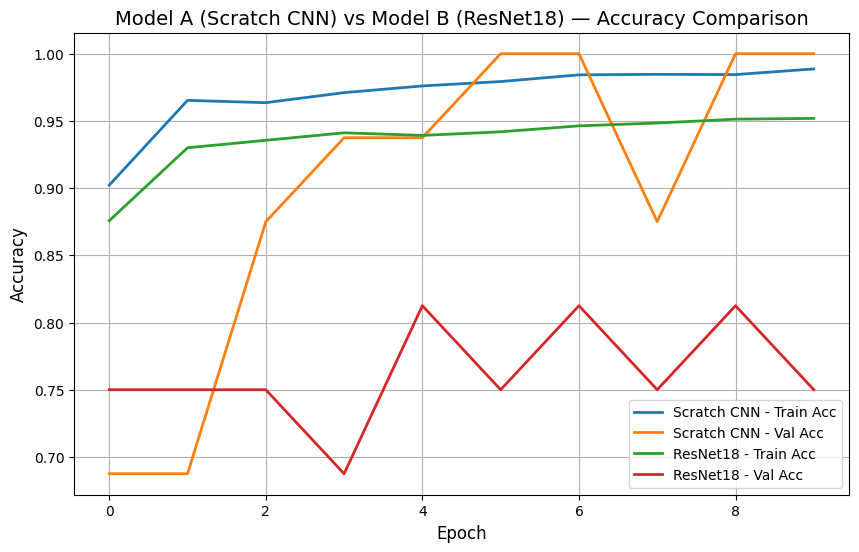

In [33]:
plt.figure(figsize=(10,6))

# Scratch CNN accuracy
plt.plot(train_accuracies, label="Scratch CNN - Train Acc", linewidth=2)
plt.plot(val_accuracies, label="Scratch CNN - Val Acc", linewidth=2)

# ResNet-18 accuracy
plt.plot(res_train_accs, label="ResNet18 - Train Acc", linewidth=2)
plt.plot(res_val_accs, label="ResNet18 - Val Acc", linewidth=2)

plt.title("Model A (Scratch CNN) vs Model B (ResNet18) — Accuracy Comparison", fontsize=14)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.grid(True)
plt.legend()
plt.show()

# **7) Test Data Comparison**

**Task: Compare the accuracies of both models on the test set**

In [34]:
scratch_test_loss, scratch_test_acc = evaluate(
    modelA, test_loader, criterion, DEVICE
)

# Evaluate ResNet-18
resnet_test_loss, resnet_test_acc = evaluate(
    resnet18, test_loader, criterion, DEVICE
)

print("====== Test Set Results ======")
print(f"Scratch CNN Test Accuracy : {scratch_test_acc:.4f}")
print(f"ResNet-18 Test Accuracy   : {resnet_test_acc:.4f}")

====== Test Set Results ======
Scratch CNN Test Accuracy : 0.7115
ResNet-18 Test Accuracy   : 0.7804


## **8) Final Analysis & Conclusion**

**Task: Write your analysis here:**
- Why the pretrained model outperformed the scratch model
- Why transfer learning is essential for small datasets
- What features ImageNet CNNs learn that transfer to medical images
- Which model generalized better and why


**Answer:**
Why the pretrained model outperformed the scratch model

Pretrained models already have better useful features learned from millions of images.They only need small adjustments for the new task whereas the scratch models must learn everything from zero with limited data also scratch models overfit and perform worse whereas the pretrained models converge faster and more accurately.

Why transfer learning is essential for small datasets

Deep Learning needs labeled datasets which medical image rarely has So transfer learning reduces this requirement by starting with a model that already knows strong visual features , helping avoid overfitting and improving accuracy even with very little data.

What features ImageNet CNNs learn that transfer to medical images

ImageNet trained CNNs learn
low-level: edges , corners and gradients.
Mid-level: textures, patterns and shapes
These are universal across images including medical scans so the pretrained filters naturally detect meaningful structures in X-rays.

Which model generalized better and why

The pretrained model generalized better.
Reason:
its learned features prevent overfitting and provide a strong starting point, while the scratch model struggles with limited data and learns less reliable patterns.


